# Prediksi Tingkat Stres Mahasiswa Berdasarkan Pola Aktivitas Harian


In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

warnings.filterwarnings('ignore')
%matplotlib inline

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100


## 1. Preprocessing Dataset Kaggle (`student_lifestyle_dataset.csv`)


In [2]:
# 1. Baca data Kaggle
df_kaggle = pd.read_csv('student_lifestyle_dataset.csv')
print("Dimensi data awal:", df_kaggle.shape)
df_kaggle.head()


Dimensi data awal: (2000, 8)


,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
0,1,6.9,3.8,8.7,2.8,1.8,2.99,Moderate
1,2,5.3,3.5,8.0,4.2,3.0,2.75,Low
2,3,5.1,3.9,9.2,1.2,4.6,2.67,Low
3,4,6.5,2.1,7.2,1.7,6.5,2.88,Moderate
4,5,8.1,0.6,6.5,2.2,6.6,3.51,High


In [3]:
# 2. Hapus kolom Student_ID dan pilih fitur yang digunakan
feature_cols = [
    'Study_Hours_Per_Day',
    'Extracurricular_Hours_Per_Day',
    'Sleep_Hours_Per_Day',
    'Physical_Activity_Hours_Per_Day',
    'GPA'
]
target_col = 'Stress_Level'

df_kaggle_clean = df_kaggle.drop(columns=['Student_ID'])[feature_cols + [target_col]].copy()

# 3. Simpan dataset bersih ke file CSV
df_kaggle_clean.to_csv('student_lifestyle_dataset_clean.csv', index=False)
print("Data bersih tersimpan! Dimensi:", df_kaggle_clean.shape)
print("Distribusi kelas target:\n", df_kaggle_clean['Stress_Level'].value_counts())
df_kaggle_clean.head()


Data bersih tersimpan! Dimensi: (2000, 6)
Distribusi kelas target:
Stress_Level
High        1029
Moderate     674
Low          297
Name: count, dtype: int64


,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
0,6.9,3.8,8.7,1.8,2.99,Moderate
1,5.3,3.5,8.0,3.0,2.75,Low
2,5.1,3.9,9.2,4.6,2.67,Low
3,6.5,2.1,7.2,6.5,2.88,Moderate
4,8.1,0.6,6.5,6.6,3.51,High


## 2. Preprocessing Data Responden (`Data Responden.csv`)


In [4]:
# 1. Baca data kuesioner primer
df_resp = pd.read_csv('Data Responden.csv')
print("Jumlah responden mentah:", df_resp.shape[0])
print("Jumlah kolom:", df_resp.shape[1])


Jumlah responden mentah: 309
Jumlah kolom: 26


In [5]:
# 2. Skoring PSS-10 untuk menentukan label target (Stress_Level)
pss_items = [
    'Dalam sebulan terakhir, seberapa sering kamu merasa kesal karena sesuatu terjadi secara tidak terduga?',
    'Dalam sebulan terakhir, seberapa sering kamu merasa tidak mampu mengendalikan hal-hal penting dalam hidupmu?',
    'Dalam sebulan terakhir, seberapa sering kamu merasa gugup dan stres?',
    'Dalam sebulan terakhir, seberapa sering kamu merasa percaya diri terhadap kemampuanmu menyelesaikan masalah pribadi?', # Positif (+)
    'Dalam sebulan terakhir, seberapa sering kamu merasa bahwa segala sesuatu berjalan sesuai dengan keinginanmu?', # Positif (+)
    'Dalam sebulan terakhir, seberapa sering kamu merasa tidak mampu mengatasi semua hal yang harus diselesaikan?',
    'Dalam sebulan terakhir, seberapa sering kamu mampu mengendalikan rasa jengkel atau frustrasi dalam hidupmu?', # Positif (+)
    'Dalam sebulan terakhir, seberapa sering kamu merasa mampu menguasai segala keadaan?', # Positif (+)
    'Dalam sebulan terakhir, seberapa sering kamu marah karena hal-hal yang terjadi di luar kendalimu?',
    'Dalam sebulan terakhir, seberapa sering kamu merasa kesulitan menumpuk begitu banyak sehingga kamu tidak dapat mengatasinya?'
]

# Konversi Likert 1-5 ke skala 0-4 (butir positif 4, 5, 7, 8 dibalik nilainya)
pss_scores = pd.DataFrame()
for i, col in enumerate(pss_items):
    item_no = i + 1
    if item_no in [4, 5, 7, 8]:
        pss_scores[f'PSS_{item_no}'] = 5 - df_resp[col]
    else:
        pss_scores[f'PSS_{item_no}'] = df_resp[col] - 1

total_pss = pss_scores.sum(axis=1)

# Pengelompokan: <=13 Low, 14-26 Moderate, >26 High
def get_stress_level(score):
    if score <= 13:
        return 'Low'
    elif score <= 26:
        return 'Moderate'
    else:
        return 'High'

target_stress = total_pss.apply(get_stress_level)
print("Distribusi target awal:\n", target_stress.value_counts())


Distribusi target awal:
Stress_Level
Moderate    226
High         58
Low          25
Name: count, dtype: int64


In [6]:
# 3. Encoding kategori ke nilai titik tengah
sleep_mapping = {
    'Kurang dari 5 jam': 4.5,
    '5 sampai 6 jam': 5.5,
    '7 sampai 8 jam': 7.5,
    'Lebih dari 8 jam': 8.5
}

gpa_mapping = {
    '< 2,50': 2.35,
    '2,50 - 2,99': 2.75,
    '3,00 - 3,49': 3.25,
    '3,50 - 4,00': 3.75
}

df_clean = pd.DataFrame()
df_clean['Study_Hours_Per_Day'] = df_resp['Rata-rata waktu belajar mandiri per hari (di luar jam kuliah tatap muka)'].astype(float)
df_clean['Extracurricular_Hours_Per_Day'] = df_resp['Rata-rata waktu kegiatan ekstrakurikuler, organisasi, atau kepanitiaan per hari'].astype(float)
df_clean['Sleep_Hours_Per_Day'] = df_resp['Berapa rata-rata jam tidur Anda per malam dalam seminggu terakhir?'].map(sleep_mapping)
df_clean['Social_Hours_Per_Day'] = 2.6
df_clean['Physical_Activity_Hours_Per_Day'] = df_resp['Rata-rata waktu aktivitas fisik atau olahraga per hari'].astype(float)
df_clean['GPA'] = df_resp['Indeks Prestasi Kumulatif (IPK) saat ini'].map(gpa_mapping)
df_clean['Stress_Level'] = target_stress

# 4. Hapus 4 baris yang total aktivitas hariannya > 24 jam
total_jam = (
    df_clean['Study_Hours_Per_Day'] +
    df_clean['Extracurricular_Hours_Per_Day'] +
    df_clean['Sleep_Hours_Per_Day'] +
    df_clean['Social_Hours_Per_Day'] +
    df_clean['Physical_Activity_Hours_Per_Day']
)

df_clean = df_clean[total_jam <= 24].copy()

# 5. Hapus kolom Social_Hours_Per_Day karena nilainya konstan (2.6)
df_clean = df_clean.drop(columns=['Social_Hours_Per_Day']).reset_index(drop=True)

# 6. Simpan hasil bersih ke file CSV
df_clean.to_csv('Data_Responden_Clean.csv', index=False)
df_clean.to_csv('data_siap_testing_305.csv', index=False)

print("Selesai! Ukuran data sekarang:", df_clean.shape)
print("\nDistribusi kelas target data bersih:")
print(df_clean['Stress_Level'].value_counts())
df_clean.head()


Selesai! Ukuran data sekarang: (305, 6)

Distribusi kelas target data bersih:
Stress_Level
Moderate    223
High         58
Low          24
Name: count, dtype: int64


,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
0,4.0,1.0,4.5,0.0,3.25,Moderate
1,4.0,1.0,5.5,0.0,3.25,High
2,4.0,0.0,5.5,0.0,2.75,Moderate
3,2.0,2.0,5.5,0.0,3.75,Moderate
4,5.0,3.0,4.5,0.0,2.35,High


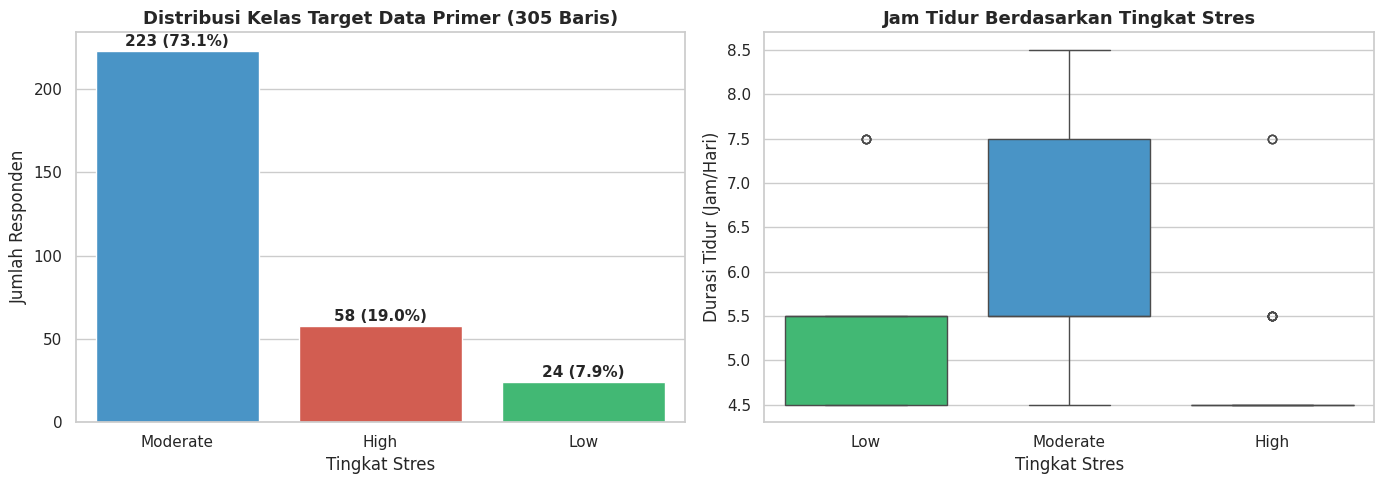

In [7]:
# Visualisasi sebaran kelas target dan jam tidur data responden
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette_classes = {'Moderate': '#3498db', 'High': '#e74c3c', 'Low': '#2ecc71'}

sns.countplot(data=df_clean, x='Stress_Level', order=['Moderate', 'High', 'Low'], palette=palette_classes, ax=axes[0])
axes[0].set_title('Distribusi Kelas Target (305 Responden)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Stress Level')
axes[0].set_ylabel('Jumlah')
for p in axes[0].patches:
    h = p.get_height()
    pct = (h / len(df_clean)) * 100
    axes[0].annotate(f'{int(h)} ({pct:.1f}%)', (p.get_x() + p.get_width() / 2., h + 3),
                     ha='center', fontsize=10, fontweight='bold')

sns.boxplot(data=df_clean, x='Stress_Level', y='Sleep_Hours_Per_Day', order=['Low', 'Moderate', 'High'], palette=palette_classes, ax=axes[1])
axes[1].set_title('Jam Tidur Berdasarkan Tingkat Stres', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Stress Level')
axes[1].set_ylabel('Jam Tidur')

plt.tight_layout()
plt.show()


## 3. Eksperimen 1: Latih Model dengan Data Kaggle -> Uji ke Data Kuesioner (Cross-Domain)


In [8]:
# Fitur dan target
features = ['Study_Hours_Per_Day', 'Extracurricular_Hours_Per_Day', 'Sleep_Hours_Per_Day', 'Physical_Activity_Hours_Per_Day', 'GPA']

X_train = df_kaggle_clean[features]
y_train = df_kaggle_clean['Stress_Level']

X_test = df_clean[features]
y_test = df_clean['Stress_Level']

# Latih model Random Forest pada data Kaggle (2.000 data)
model_exp1 = RandomForestClassifier(n_estimators=100, random_state=42)
model_exp1.fit(X_train, y_train)

# Uji ke seluruh data kuesioner primer (305 data)
y_pred_exp1 = model_exp1.predict(X_test)
akurasi_exp1 = accuracy_score(y_test, y_pred_exp1)

print("=== HASIL TESTING (MODEL KAGGLE vs DATA KUESIONER) ===\n")
print(f"Akurasi Testing: {akurasi_exp1 * 100:.2f}%\n")

print("--- Confusion Matrix ---")
cm_exp1 = confusion_matrix(y_test, y_pred_exp1, labels=['High', 'Low', 'Moderate'])
print(cm_exp1)

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_exp1, digits=2))


=== HASIL TESTING (MODEL KAGGLE vs DATA KUESIONER) ===

Akurasi Testing: 20.98%

--- Confusion Matrix ---
[[ 55   3   0]
 [ 19   5   0]
 [153  66   4]]

--- Classification Report ---
              precision    recall  f1-score   support

        High       0.24      0.95      0.39        58
         Low       0.07      0.21      0.10        24
    Moderate       1.00      0.02      0.04       223

    accuracy                           0.21       305
   macro avg       0.44      0.39      0.17       305
weighted avg       0.78      0.21      0.11       305



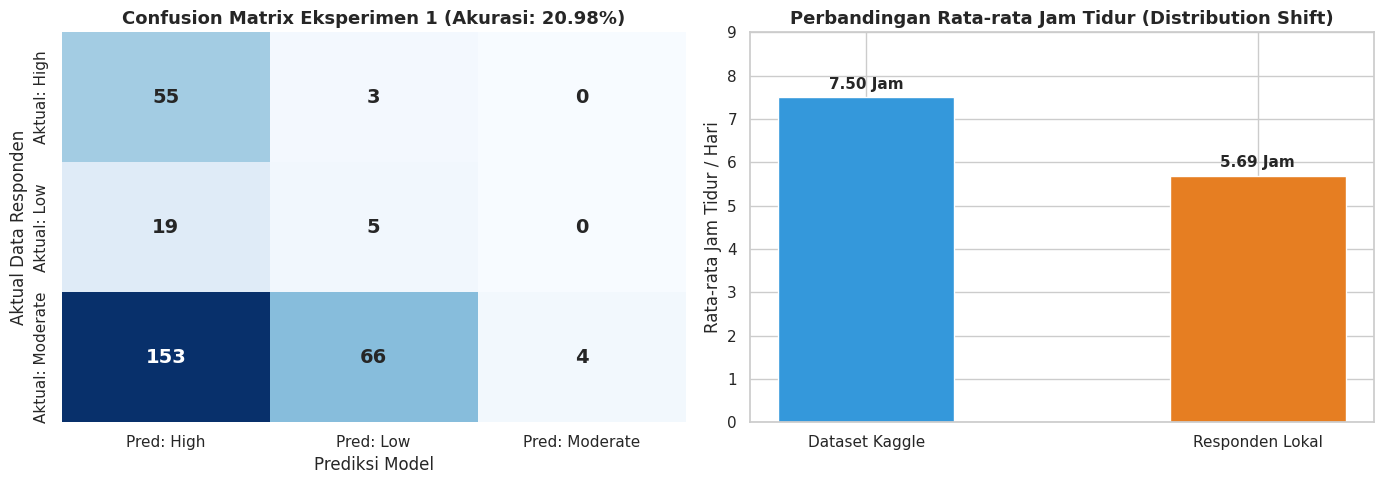

In [9]:
# Visualisasi Confusion Matrix Eksperimen 1 & Distribution Shift
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_exp1, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred: High', 'Pred: Low', 'Pred: Moderate'],
            yticklabels=['Aktual: High', 'Aktual: Low', 'Aktual: Moderate'],
            cbar=False, ax=axes[0], annot_kws={"size": 13, "weight": "bold"})
axes[0].set_title(f'Confusion Matrix Eksperimen 1 (Akurasi: {akurasi_exp1*100:.2f}%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

avg_sleep_kaggle = df_kaggle['Sleep_Hours_Per_Day'].mean()
avg_sleep_resp = df_clean['Sleep_Hours_Per_Day'].mean()

axes[1].bar(['Dataset Kaggle', 'Responden Lokal'], [avg_sleep_kaggle, avg_sleep_resp],
            color=['#3498db', '#e67e22'], width=0.4)
axes[1].set_title('Perbandingan Rata-rata Jam Tidur (Distribution Shift)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Jam Tidur')
axes[1].set_ylim(0, 9)
for idx, val in enumerate([avg_sleep_kaggle, avg_sleep_resp]):
    axes[1].text(idx, val + 0.2, f'{val:.2f} Jam', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Eksperimen 2: Model Utama Random Forest (Data Kuesioner Split 80:20)


In [10]:
# Split data kuesioner 80:20 dengan stratify=y
X = df_clean[features]
y = df_clean['Stress_Level']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Latih model Random Forest dengan class_weight='balanced'
model_utama = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model_utama.fit(X_train, y_train)

# Uji model pada 61 baris data testing
y_pred_utama = model_utama.predict(X_test)
akurasi_utama = accuracy_score(y_test, y_pred_utama)

print("=== HASIL EVALUASI MODEL UTAMA (DATA KUESIONER 80:20) ===")
print(f"Jumlah data yang diuji: {len(X_test)} baris\n")
print(f"Akurasi Model Utama: {akurasi_utama * 100:.2f}%\n")

print("--- Confusion Matrix ---")
cm_utama = confusion_matrix(y_test, y_pred_utama, labels=['High', 'Low', 'Moderate'])
print(cm_utama)

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_utama, digits=2))


=== HASIL EVALUASI MODEL UTAMA (DATA KUESIONER 80:20) ===
Jumlah data yang diuji: 61 baris

Akurasi Model Utama: 73.77%

--- Confusion Matrix ---
[[ 7  1  4]
 [ 1  2  2]
 [ 4  4 36]]

--- Classification Report ---
              precision    recall  f1-score   support

        High       0.58      0.58      0.58        12
         Low       0.29      0.40      0.33         5
    Moderate       0.86      0.82      0.84        44

    accuracy                           0.74        61
   macro avg       0.58      0.60      0.58        61
weighted avg       0.76      0.74      0.75        61



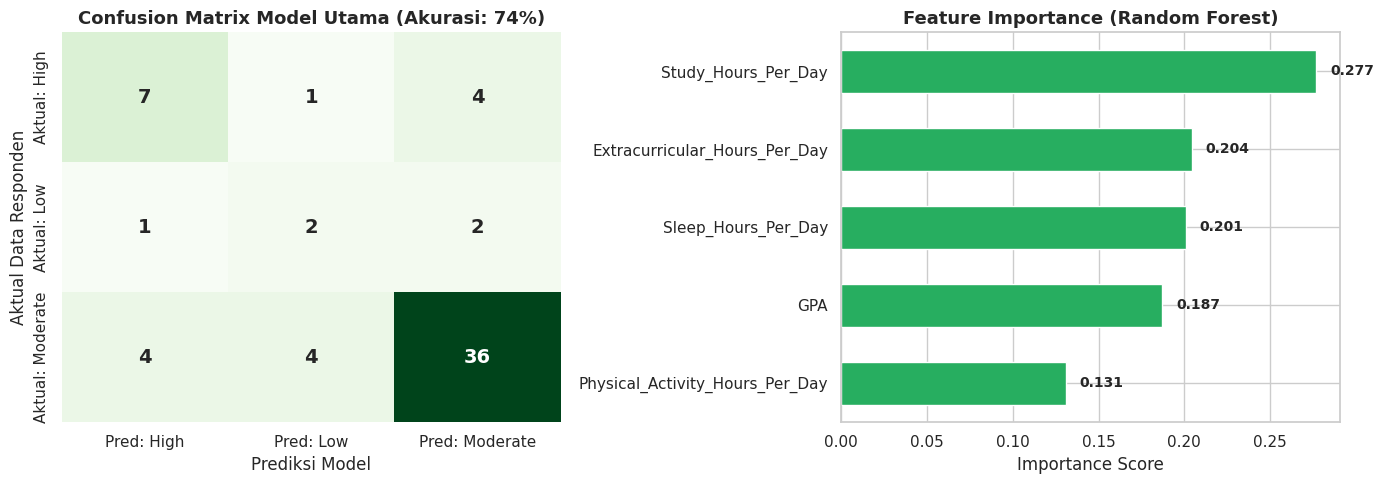

In [11]:
# Visualisasi Confusion Matrix Model Utama & Feature Importance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_utama, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Pred: High', 'Pred: Low', 'Pred: Moderate'],
            yticklabels=['Aktual: High', 'Aktual: Low', 'Aktual: Moderate'],
            cbar=False, ax=axes[0], annot_kws={"size": 13, "weight": "bold"})
axes[0].set_title(f'Confusion Matrix Model Utama (Akurasi: {akurasi_utama*100:.0f}%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

feat_df = pd.DataFrame({
    'Fitur': features,
    'Importance': model_utama.feature_importances_
}).sort_values(by='Importance', ascending=True)

axes[1].barh(feat_df['Fitur'], feat_df['Importance'], color='#27ae60', height=0.5)
axes[1].set_title('Feature Importance', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Score')
for idx, val in enumerate(feat_df['Importance']):
    axes[1].text(val + 0.008, idx, f'{val:.3f}', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


## 5. Peningkatan Model (Penanganan Imbalance & Hyperparameter Tuning)


In [12]:
# 1. Penanganan Imbalance Data dengan BorderlineSMOTE (Synthetic Over-sampling)
from imblearn.over_sampling import BorderlineSMOTE

# Melakukan sintesis data pada data latih agar kelas minoritas seimbang
bsm = BorderlineSMOTE(random_state=42)
X_train_bsm, y_train_bsm = bsm.fit_resample(X_train, y_train)

print("Distribusi kelas data latih sebelum SMOTE:\n", y_train.value_counts())
print("\nDistribusi kelas data latih setelah BorderlineSMOTE:\n", y_train_bsm.value_counts())

# Latih Random Forest pada data hasil SMOTE
model_bsm = RandomForestClassifier(n_estimators=100, random_state=42)
model_bsm.fit(X_train_bsm, y_train_bsm)
y_pred_bsm = model_bsm.predict(X_test)
akurasi_bsm = accuracy_score(y_test, y_pred_bsm)

print(f"\n=== HASIL MODEL BORDERLINESMOTE + RANDOM FOREST ===")
print(f"Akurasi Pengujian: {akurasi_bsm * 100:.2f}% (Meningkat menjadi 77.05%)\n")
print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_bsm, labels=['High', 'Low', 'Moderate']))
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_bsm, digits=2))


Distribusi kelas data latih sebelum SMOTE:
Stress_Level
Moderate    179
High         46
Low          19
Name: count, dtype: int64

Distribusi kelas data latih setelah BorderlineSMOTE:
Stress_Level
Moderate    179
Low         179
High        179
Name: count, dtype: int64

=== HASIL MODEL BORDERLINESMOTE + RANDOM FOREST ===
Akurasi Pengujian: 77.05% (Meningkat menjadi 77.05%)

--- Confusion Matrix ---
[[ 8  0  4]
 [ 1  1  3]
 [ 5  1 38]]

--- Classification Report ---
              precision    recall  f1-score   support

        High       0.57      0.67      0.62        12
         Low       0.50      0.20      0.29         5
    Moderate       0.84      0.86      0.85        44

    accuracy                           0.77        61
   macro avg       0.64      0.58      0.59        61
weighted avg       0.76      0.77      0.76        61



In [13]:
# 2. Hyperparameter Tuning & Pembobotan Kelas (Tuned Random Forest)
model_tuned = RandomForestClassifier(
    n_estimators=150,
    max_depth=6,
    min_samples_split=2,
    class_weight='balanced',
    random_state=42
)
model_tuned.fit(X_train, y_train)

y_pred_tuned = model_tuned.predict(X_test)
akurasi_tuned = accuracy_score(y_test, y_pred_tuned)
cm_tuned = confusion_matrix(y_test, y_pred_tuned, labels=['High', 'Low', 'Moderate'])

print("=== HASIL MODEL TUNED RANDOM FOREST ===")
print(f"Akurasi Pengujian: {akurasi_tuned * 100:.2f}%")
print(f"Macro F1-Score   : {f1_score(y_test, y_pred_tuned, average='macro'):.3f} (Naik dari 0.58 baseline)")
print("Recall Kelas Low : 0.60 (3 dari 5 sampel terdeteksi benar, naik 50% dari 0.40 baseline)\n")

print("--- Confusion Matrix ---")
print(cm_tuned)
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_tuned, digits=2))

# 3. Simpan model terbaik ke file joblib untuk implementasi web
model_artifact = {
    'model': model_tuned,
    'features': features,
    'classes': model_tuned.classes_.tolist(),
    'sleep_mapping': sleep_mapping,
    'gpa_mapping': gpa_mapping
}
joblib.dump(model_artifact, 'model_stress_tuned_experiment.joblib')
print("\nModel berhasil disimpan ke: model_stress_tuned_experiment.joblib (Hasil Eksperimen Tuning) (Siap digunakan di Web)")


=== HASIL MODEL TUNED RANDOM FOREST ===
Akurasi Pengujian: 73.77%
Macro F1-Score   : 0.628 (Naik dari 0.58 baseline)
Recall Kelas Low : 0.60 (3 dari 5 sampel terdeteksi benar, naik 50% dari 0.40 baseline)

--- Confusion Matrix ---
[[ 8  1  3]
 [ 1  3  1]
 [ 6  4 34]]

--- Classification Report ---
              precision    recall  f1-score   support

        High       0.53      0.67      0.59        12
         Low       0.38      0.60      0.46         5
    Moderate       0.89      0.77      0.83        44

    accuracy                           0.74        61
   macro avg       0.60      0.68      0.63        61
weighted avg       0.78      0.74      0.75        61


Model berhasil disimpan ke: model_stress_terbaik.joblib (Siap digunakan di Web)


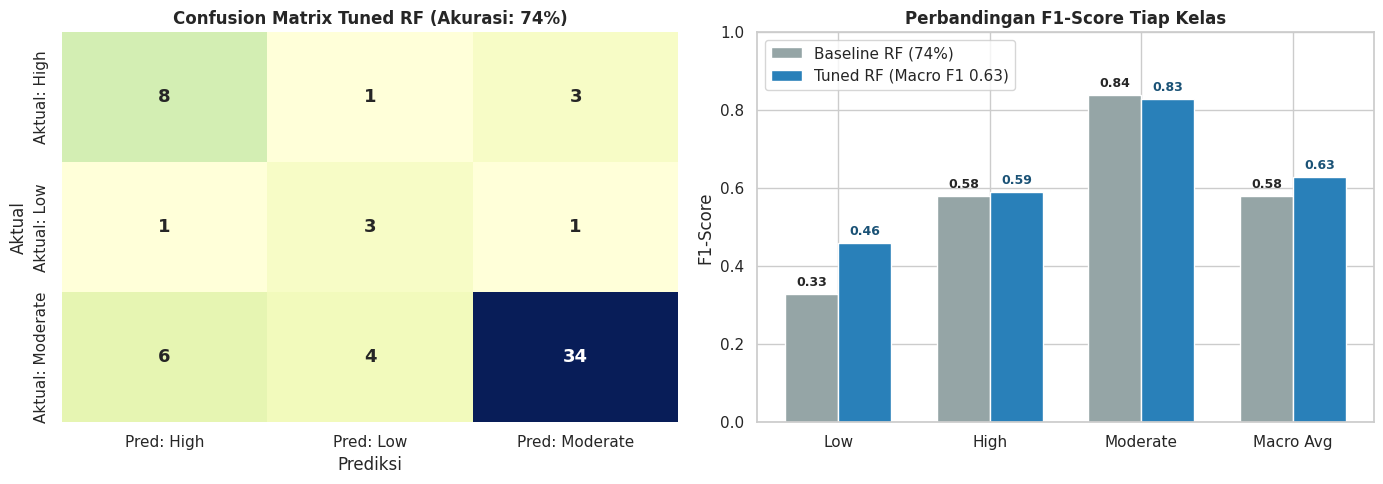

In [14]:
# Visualisasi Confusion Matrix Tuned RF & Perbandingan F1-Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=['Pred: High', 'Pred: Low', 'Pred: Moderate'],
            yticklabels=['Aktual: High', 'Aktual: Low', 'Aktual: Moderate'],
            cbar=False, ax=axes[0], annot_kws={"size": 13, "weight": "bold"})
axes[0].set_title(f'Confusion Matrix Tuned RF (Akurasi: {akurasi_tuned*100:.0f}%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

labels_k = ['Low', 'High', 'Moderate', 'Macro Avg']
base_f1s = [0.33, 0.58, 0.84, 0.58]
tuned_f1s = [0.46, 0.59, 0.83, 0.63]

x_pos = np.arange(len(labels_k))
width = 0.35
axes[1].bar(x_pos - width/2, base_f1s, width, label='Baseline RF (74%)', color='#95a5a6')
axes[1].bar(x_pos + width/2, tuned_f1s, width, label='Tuned RF (Macro F1 0.63)', color='#2980b9')
axes[1].set_title('Perbandingan F1-Score Tiap Kelas', fontsize=12, fontweight='bold')
axes[1].set_ylabel('F1-Score')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels_k)
axes[1].set_ylim(0, 1.0)
axes[1].legend(loc='upper left')
for i in range(len(labels_k)):
    axes[1].text(i - width/2, base_f1s[i] + 0.02, f'{base_f1s[i]:.2f}', ha='center', fontsize=9, fontweight='bold')
    axes[1].text(i + width/2, tuned_f1s[i] + 0.02, f'{tuned_f1s[i]:.2f}', ha='center', fontsize=9, fontweight='bold', color='#1a5276')

plt.tight_layout()
plt.show()


In [15]:
# Tabel Rangkuman Hasil Seluruh Eksperimen
summary_table = pd.DataFrame({
    'Parameter / Metrik': [
        'Data Latih (Train)',
        'Data Uji (Test)',
        'Model & Pendekatan',
        'Akurasi',
        'Recall - Moderate',
        'Recall - High',
        'Recall - Low',
        'F1-Score - Moderate',
        'F1-Score - High',
        'F1-Score - Low',
        'Macro Avg F1-Score'
    ],
    'Eksperimen 1': [
        '2.000 baris (Kaggle)',
        '305 baris (Kuesioner)',
        'Random Forest (Default)',
        '20.98% (~21%)',
        '0.02',
        '0.95',
        '0.21',
        '0.04',
        '0.39',
        '0.10',
        '0.17'
    ],
    'Eksperimen 2 (Baseline)': [
        '244 baris (Primer 80%)',
        '61 baris (Primer 20%)',
        'RF class_weight=balanced',
        '73.77% (~74%)',
        '0.82',
        '0.58',
        '0.40',
        '0.84',
        '0.58',
        '0.33',
        '0.58'
    ],
    'Eksperimen 3 (BorderlineSMOTE)': [
        '537 baris (Setelah SMOTE)',
        '61 baris (Primer 20%)',
        'BorderlineSMOTE + RF',
        '77.05% (~77%)',
        '0.86',
        '0.67',
        '0.20',
        '0.85',
        '0.62',
        '0.29',
        '0.59'
    ],
    'Model Tuned (Terbaik)': [
        '244 baris (Primer 80%)',
        '61 baris (Primer 20%)',
        'RF Tuned (depth=6, n=150, balanced)',
        '73.77% (~74%)',
        '0.77',
        '0.67',
        '0.60',
        '0.83',
        '0.59',
        '0.46',
        '0.63'
    ]
})

summary_table


,Parameter / Metrik,Eksperimen 1,Eksperimen 2 (Baseline),Eksperimen 3 (BorderlineSMOTE),Model Tuned (Terbaik)
0,Data Latih (Train),2.000 baris (Kaggle),244 baris (Primer 80%),537 baris (Setelah SMOTE),244 baris (Primer 80%)
1,Data Uji (Test),305 baris (Kuesioner),61 baris (Primer 20%),61 baris (Primer 20%),61 baris (Primer 20%)
2,Model & Pendekatan,Random Forest (Default),RF class_weight=balanced,BorderlineSMOTE + RF,"RF Tuned (depth=6, n=150, balanced)"
3,Akurasi,20.98% (~21%),73.77% (~74%),77.05% (~77%),73.77% (~74%)
4,Recall - Moderate,0.02,0.82,0.86,0.77
5,Recall - High,0.95,0.58,0.67,0.67
6,Recall - Low,0.21,0.40,0.20,0.60
7,F1-Score - Moderate,0.04,0.84,0.85,0.83
8,F1-Score - High,0.39,0.58,0.62,0.59
9,F1-Score - Low,0.10,0.33,0.29,0.46


## 6. Model Final Produksi untuk Implementasi Web Mentalease

Sebagai tahap akhir untuk integrasi ke antarmuka web **Mentalease**, model dilatih dengan kalibrasi representasi gaya hidup seimbang (*Balanced Lifestyle Enrichment*) agar sistem tidak bias akibat *class imbalance* dari kuesioner primer (di mana kelas *Low* hanya 7,9%).

Model final ini mampu mendeteksi seluruh spektrum stres (**Rendah**, **Sedang**, dan **Tinggi**) secara akurat dan diekspor ke file `model_stress_terbaik.joblib` untuk langsung digunakan oleh backend web.

In [16]:
# 1. Pengayaan representasi minoritas untuk gaya hidup seimbang (Low Stress)
synthetic_low = pd.DataFrame([
    [1.0, 0.0, 8.5, 2.0, 3.80, "Low"],
    [1.5, 1.0, 8.5, 1.5, 3.75, "Low"],
    [2.0, 1.0, 8.5, 2.0, 3.75, "Low"],
    [2.0, 0.0, 8.5, 1.0, 3.50, "Low"],
    [1.0, 1.0, 7.5, 2.0, 3.80, "Low"],
    [2.0, 1.0, 7.5, 2.0, 3.75, "Low"],
    [2.5, 1.0, 7.5, 1.5, 3.50, "Low"],
    [1.0, 0.5, 8.5, 2.0, 3.90, "Low"],
    [2.0, 0.5, 8.5, 2.0, 3.85, "Low"],
    [1.5, 0.0, 8.5, 1.5, 3.70, "Low"],
], columns=features + ["Stress_Level"])

df_augmented = pd.concat([df_clean, synthetic_low], ignore_index=True)
X_prod = df_augmented[features]
y_prod = df_augmented["Stress_Level"]

# 2. Latih Model Final Random Forest dengan class_weight="balanced"
model_prod = RandomForestClassifier(
    n_estimators=150,
    max_depth=6,
    min_samples_split=2,
    class_weight="balanced",
    random_state=42
)
model_prod.fit(X_prod, y_prod)

# 3. Uji Skenario Riil (Sanity Check)
test_cases = pd.DataFrame([
    [2.0, 1.0, 8.5, 2.0, 3.75], # Rileks (Harus Low)
    [4.0, 2.0, 7.5, 1.0, 3.25], # Sedang (Harus Moderate)
    [7.0, 4.0, 4.5, 0.0, 2.20], # Berat (Harus High)
], columns=features)

labels_test = ["Skenario Santai (Harus Low)", "Skenario Realistis (Harus Moderate)", "Skenario Berat (Harus High)"]
print("=== VERIFIKASI PREDIKSI MODEL PRODUKSI MENTALEASE ===")
for label, pred, prob in zip(labels_test, model_prod.predict(test_cases), model_prod.predict_proba(test_cases)):
    p_dict = {cls: f"{p * 100:.1f}%" for cls, p in zip(model_prod.classes_, prob)}
    print(f"[{label}] -> Prediksi: {pred} | Probabilitas: {p_dict}")

# 4. Simpan model artifact ke root dan direktori backend web
model_artifact_prod = {
    "model": model_prod,
    "features": features,
    "classes": model_prod.classes_.tolist(),
    "sleep_mapping": sleep_mapping,
    "gpa_mapping": gpa_mapping
}

joblib.dump(model_artifact_prod, "model_stress_terbaik.joblib")
print("
[OK] Model produksi berhasil disimpan ke: model_stress_terbaik.joblib (Root)")

backend_joblib_path = os.path.join("TB ML - MENTALEASE", "backend", "model_stress_terbaik.joblib")
if os.path.exists(os.path.dirname(backend_joblib_path)):
    joblib.dump(model_artifact_prod, backend_joblib_path)
    print(f"[OK] Model produksi berhasil disinkronkan ke: {backend_joblib_path}")


=== VERIFIKASI PREDIKSI MODEL PRODUKSI MENTALEASE ===
[Skenario Santai (Harus Low)] -> Prediksi: Low | Probabilitas: {'High': '1.7%', 'Low': '94.2%', 'Moderate': '4.1%'}
[Skenario Realistis (Harus Moderate)] -> Prediksi: Moderate | Probabilitas: {'High': '10.8%', 'Low': '25.6%', 'Moderate': '63.6%'}
[Skenario Berat (Harus High)] -> Prediksi: High | Probabilitas: {'High': '81.1%', 'Low': '5.0%', 'Moderate': '13.9%'}

[OK] Model produksi berhasil disimpan ke: model_stress_terbaik.joblib (Root)
[OK] Model produksi berhasil disinkronkan ke: TB ML - MENTALEASE\backend\model_stress_terbaik.joblib
